<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/solitons/soliton_ch04_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*TASI Lectures on Solitons* — `soliton_ch04_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Solitons Ch 4 · Domain Walls — Figure Notebook
Based on D. Tong, TASI Lectures on Solitons

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
import os

BG   = '#1e1e2e'; FG = '#cdd6f4'; EDGE = '#45475a'
AMB  = '#e8a838'; YELL = '#f9c74f'; GREEN = '#90ee90'
RED  = '#e07070'; PURP = '#c792ea'; BLUE = '#89c4f4'; TEAL = '#2ec4b6'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.25,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': AMB, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

CH = 'ch04'
os.makedirs(f'figures/{CH}', exist_ok=True)

def save(name, fig):
    fig.savefig(f'figures/{CH}/{name}', dpi=150, bbox_inches='tight', facecolor=BG)
    plt.show()
    print(f'Saved: figures/{CH}/{name}')

print('Setup complete.')


Setup complete.


## Fig 01 · BPS Domain Wall Profile

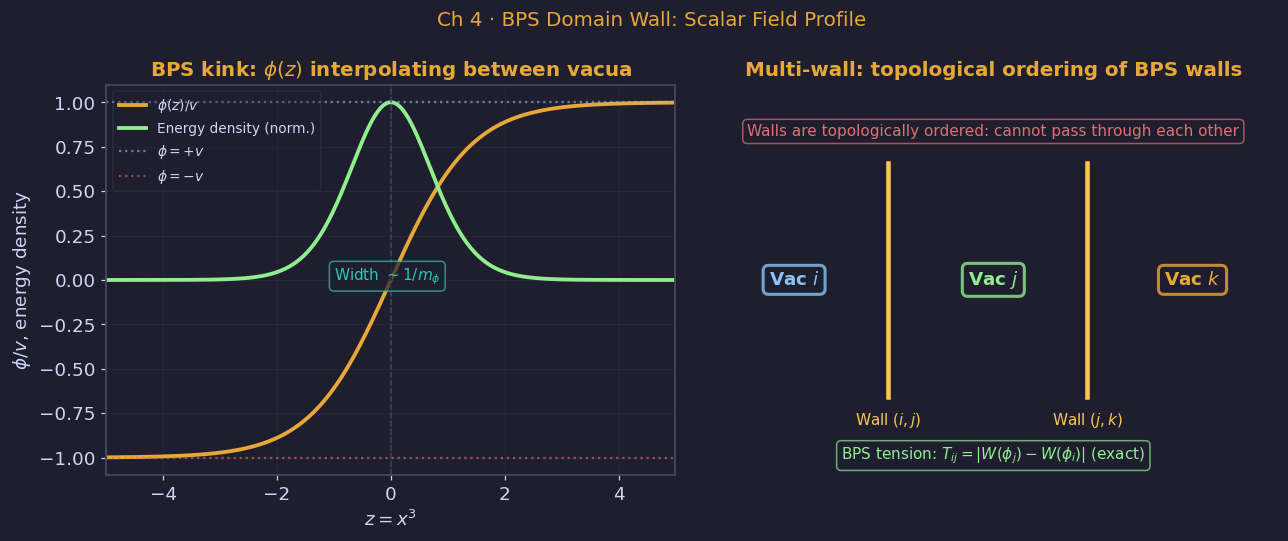

Saved: figures/ch04/fig01_domain_wall_profile.png


In [2]:
# ── fig01: domain wall profile ───────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(r"Ch 4 · BPS Domain Wall: Scalar Field Profile", color=AMB, fontsize=13)

z = np.linspace(-5, 5, 400)
v = 1.0
# BPS kink: phi = v * tanh(v*z/sqrt(2)) for V = lambda/4*(phi^2-v^2)^2
phi_kink = v * np.tanh(v * z / np.sqrt(2))
# Energy density: T_{00} = (dphi/dz)^2 = v^4/2 * sech^4(v*z/sqrt(2))
energy   = (v**2 / np.sqrt(2))**2 / np.cosh(v * z / np.sqrt(2))**4

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r"BPS kink: $\phi(z)$ interpolating between vacua", color=AMB)
ax.plot(z, phi_kink/v, color=AMB, lw=2.5, label=r'$\phi(z)/v$')
ax.plot(z, energy/energy.max(), color=GREEN, lw=2.5, label=r'Energy density (norm.)')
ax.axhline( 1.0, color=BLUE, ls=':', lw=1.5, alpha=0.6, label=r'$\phi=+v$')
ax.axhline(-1.0, color=RED,  ls=':', lw=1.5, alpha=0.6, label=r'$\phi=-v$')
ax.axvline( 0.0, color=EDGE, ls='--', lw=1.0)
ax.set_xlabel(r'$z = x^3$'); ax.set_ylabel(r'$\phi/v$, energy density')
ax.legend(fontsize=9); ax.grid(True, alpha=0.2); ax.set_xlim(-5, 5)
ax.text(0.40, 0.50, r"Width $\sim 1/m_\phi$", transform=ax.transAxes,
        fontsize=10, color=TEAL,
        bbox=dict(boxstyle='round', fc=BG, ec=TEAL, alpha=0.7))

# Right: multi-wall schematic
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title(r"Multi-wall: topological ordering of BPS walls", color=AMB)
vacua  = [r"Vac $i$", r"Vac $j$", r"Vac $k$"]
colors = [BLUE, GREEN, AMB]
xpos   = [0.15, 0.50, 0.85]
for x, label, col in zip(xpos, vacua, colors):
    ax2.text(x, 0.50, label, ha='center', va='center', fontsize=12,
             fontweight='bold', color=col, transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=col, lw=2, alpha=0.8))

# Wall boundaries
for xw, lbl in [(0.315, r"Wall $(i,j)$"), (0.665, r"Wall $(j,k)$")]:
    ax2.plot([xw, xw], [0.20, 0.80], color=YELL, lw=3, transform=ax2.transAxes)
    ax2.text(xw, 0.14, lbl, ha='center', va='center', fontsize=10,
             color=YELL, transform=ax2.transAxes)

ax2.text(0.50, 0.88, r"Walls are topologically ordered: cannot pass through each other",
         ha='center', va='center', fontsize=10, color=RED, transform=ax2.transAxes,
         bbox=dict(boxstyle='round', fc=BG, ec=RED, alpha=0.7))
ax2.text(0.50, 0.05, r"BPS tension: $T_{ij} = |W(\phi_j)-W(\phi_i)|$ (exact)",
         ha='center', va='center', fontsize=10, color=GREEN, transform=ax2.transAxes,
         bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.7))
plt.tight_layout()
save('fig01_domain_wall_profile.png', fig)


## Fig 02 · Wall Ordering and Moduli Space

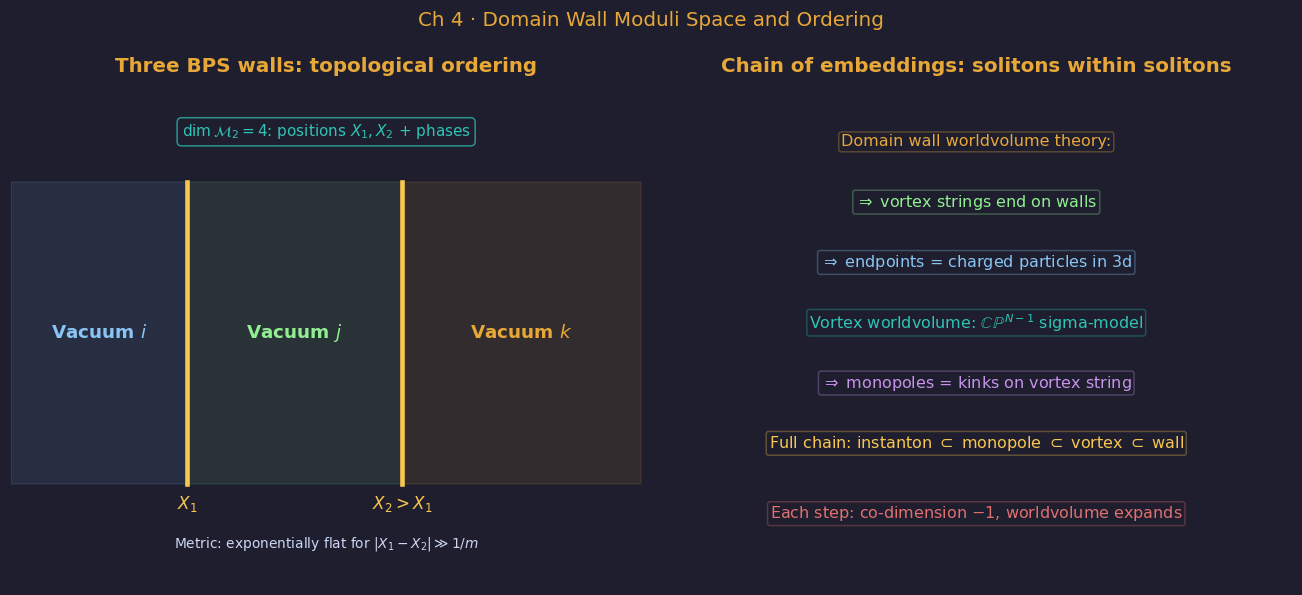

Saved: figures/ch04/fig02_wall_ordering.png


In [3]:
# ── fig02: wall ordering and moduli space ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle(r"Ch 4 · Domain Wall Moduli Space and Ordering", color=AMB, fontsize=13)

# Left: three consecutive walls
ax = axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title(r"Three BPS walls: topological ordering", color=AMB)

regions = [(0.00, 0.28, BLUE, r"Vacuum $i$"),
           (0.28, 0.62, GREEN, r"Vacuum $j$"),
           (0.62, 1.00, AMB,   r"Vacuum $k$")]
for (x0, x1, col, lbl) in regions:
    ax.fill_between([x0, x1], [0.20, 0.20], [0.80, 0.80],
                    color=col, alpha=0.10, transform=ax.transAxes)
    ax.text((x0+x1)/2, 0.50, lbl, ha='center', va='center', fontsize=12,
            fontweight='bold', color=col, transform=ax.transAxes)

for xw in [0.28, 0.62]:
    ax.plot([xw, xw], [0.20, 0.80], color=YELL, lw=3, transform=ax.transAxes)

ax.text(0.28, 0.15, r"$X_1$", ha='center', fontsize=11, color=YELL,
        transform=ax.transAxes)
ax.text(0.62, 0.15, r"$X_2 > X_1$", ha='center', fontsize=11, color=YELL,
        transform=ax.transAxes)
ax.text(0.50, 0.90, r"$\dim\mathcal{M}_2 = 4$: positions $X_1, X_2$ + phases",
        ha='center', va='center', fontsize=10, color=TEAL, transform=ax.transAxes,
        bbox=dict(boxstyle='round', fc=BG, ec=TEAL, alpha=0.7))
ax.text(0.50, 0.08, r"Metric: exponentially flat for $|X_1-X_2|\gg 1/m$",
        ha='center', va='center', fontsize=9, color=FG, transform=ax.transAxes)

# Right: soliton-in-soliton web
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title("Chain of embeddings: solitons within solitons", color=AMB)
items = [
    (0.50, 0.88, r"Domain wall worldvolume theory:", AMB),
    (0.50, 0.76, r"$\Rightarrow$ vortex strings end on walls", GREEN),
    (0.50, 0.64, r"$\Rightarrow$ endpoints = charged particles in 3d", BLUE),
    (0.50, 0.52, r"Vortex worldvolume: $\mathbb{CP}^{N-1}$ sigma-model", TEAL),
    (0.50, 0.40, r"$\Rightarrow$ monopoles = kinks on vortex string", PURP),
    (0.50, 0.28, r"Full chain: instanton $\subset$ monopole $\subset$ vortex $\subset$ wall", YELL),
    (0.50, 0.14, r"Each step: co-dimension $-1$, worldvolume expands", RED),
]
for (x, y, txt, col) in items:
    ax2.text(x, y, txt, ha='center', va='center', fontsize=10.5,
             color=col, transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec=col, alpha=0.30))
plt.tight_layout()
save('fig02_wall_ordering.png', fig)


## Fig 03 · Complete Soliton Web

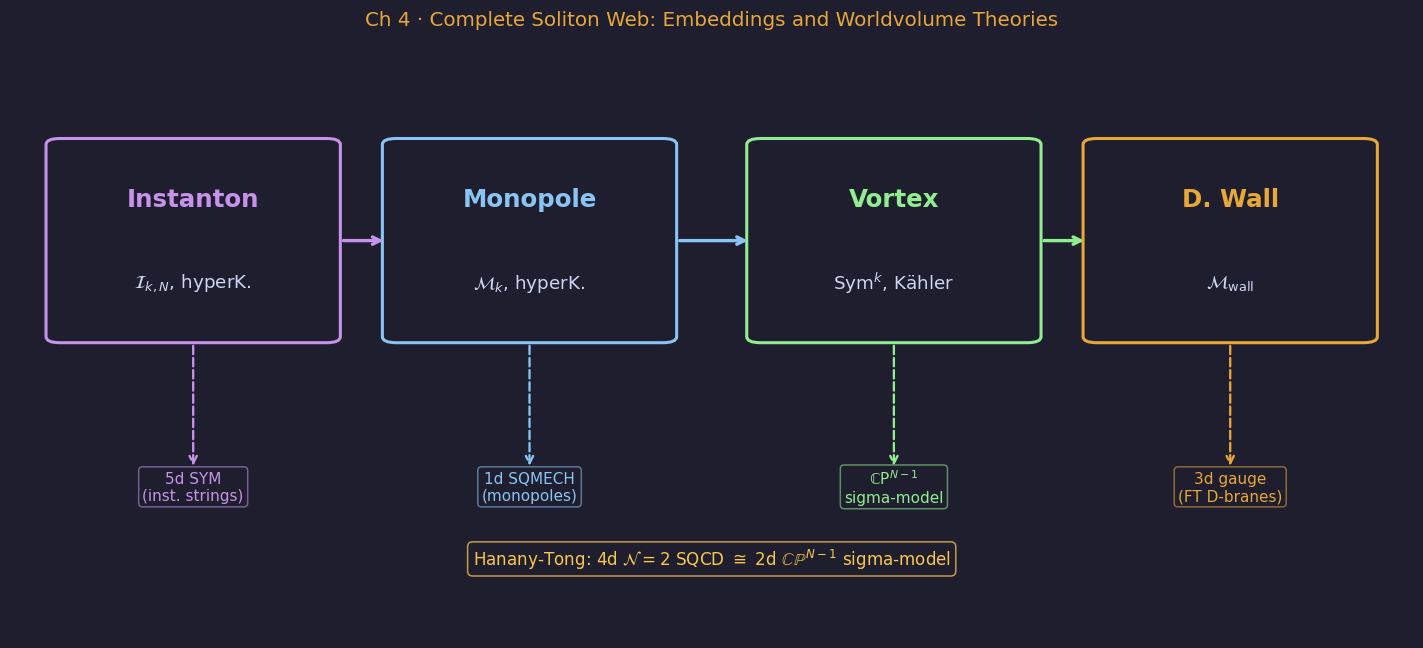

Saved: figures/ch04/fig03_soliton_web.png


In [4]:
# ── fig03: soliton web / embeddings (revised v2) ─────────────────────────
fig, ax = plt.subplots(figsize=(13, 6))
fig.suptitle("Ch 4 · Complete Soliton Web: Embeddings and Worldvolume Theories",
             color=AMB, fontsize=13, y=0.97)
ax.set_facecolor(BG); ax.axis('off')

# ── 박스 좌표: 4개 균등, 좌우 여백 확보 ──────────────────────────────────
BOX_W, BOX_H = 0.19, 0.32
BOX_Y0 = 0.50
BOX_CY = BOX_Y0 + BOX_H / 2
CXS = [0.13, 0.37, 0.63, 0.87]   # 중심 x; 좌끝=0.035, 우끝=0.965

nodes = [
    (CXS[0], "Instanton", r"$\mathcal{I}_{k,N}$, hyperK.", PURP),
    (CXS[1], "Monopole",  r"$\mathcal{M}_k$, hyperK.",      BLUE),
    (CXS[2], "Vortex",    "Sym$^k$, K\u00e4hler",           GREEN),  # ä = unicode
    (CXS[3], "D. Wall",   r"$\mathcal{M}_{\rm wall}$",       AMB),
]

for (cx, name, sub, col) in nodes:
    rect = FancyBboxPatch((cx - BOX_W/2, BOX_Y0), BOX_W, BOX_H,
                          boxstyle="round,pad=0.01", lw=2,
                          edgecolor=col, facecolor=BG, transform=ax.transAxes)
    ax.add_patch(rect)
    ax.text(cx, BOX_CY + 0.07, name,
            ha='center', va='center', fontsize=16, fontweight='bold',
            color=col, transform=ax.transAxes)
    ax.text(cx, BOX_CY - 0.07, sub,
            ha='center', va='center', fontsize=12,
            color=FG, transform=ax.transAxes)

# ── 수평 화살표: 박스 경계 정확히 연결 ───────────────────────────────────
for i in range(3):
    x_start = CXS[i]   + BOX_W/2
    x_end   = CXS[i+1] - BOX_W/2
    col     = nodes[i][3]
    ax.annotate('', xy=(x_end-0.007, BOX_CY), xytext=(x_start +0.01, BOX_CY),
                xycoords='axes fraction', textcoords='axes fraction',
                arrowprops=dict(arrowstyle='->', color=col, lw=2.2))

# ── Worldvolume theories: 박스 하단 → 레이블 ─────────────────────────────
WV_Y = 0.17
wv = [
    (CXS[0], "5d SYM\n(inst. strings)",              PURP),
    (CXS[1], "1d SQMECH\n(monopoles)",                BLUE),
    (CXS[2], "\u2102P$^{N-1}$\nsigma-model",         GREEN),
    (CXS[3], "3d gauge\n(FT D-branes)",               AMB),
]
for (cx, lbl, col) in wv:
    ax.annotate('', xy=(cx, WV_Y + 0.11), xytext=(cx, BOX_Y0 - 0.01),
                xycoords='axes fraction', textcoords='axes fraction',
                arrowprops=dict(arrowstyle='->', color=col, lw=1.5,
                                linestyle='dashed'))
    ax.text(cx, WV_Y+0.08, lbl,
            ha='center', va='center', fontsize=10, color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=col, alpha=0.55))

# ── Hanany-Tong duality ───────────────────────────────────────────────────
ax.text(0.50, 0.13,
        r"Hanany-Tong: 4d $\mathcal{N}=2$ SQCD $\cong$ 2d $\mathbb{CP}^{N-1}$ sigma-model",
        ha='center', va='center', fontsize=11, color=YELL,
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=YELL, alpha=0.75))

fig.subplots_adjust(top=0.93, bottom=0.02, left=0.01, right=0.99)
save('fig03_soliton_web.png', fig)

## Fig 04 · Field Theory D-Branes

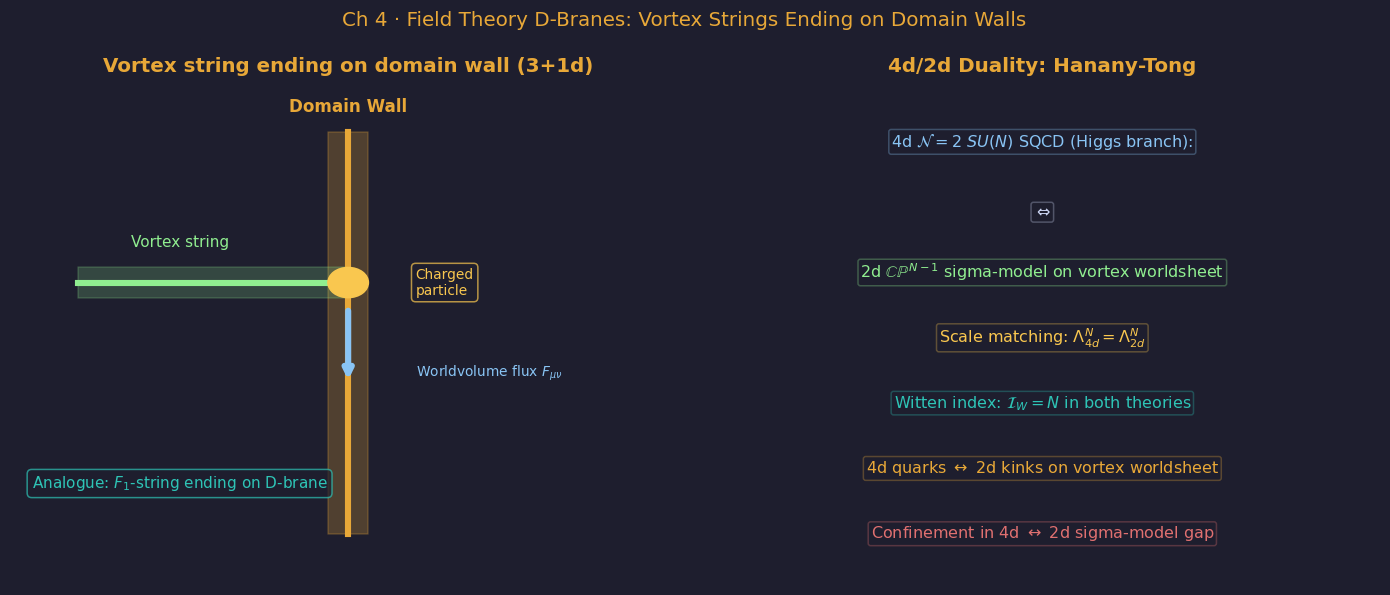

Saved: figures/ch04/fig04_field_theory_dbrane.png


In [5]:
# ── fig04: field theory D-branes ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle(r"Ch 4 · Field Theory D-Branes: Vortex Strings Ending on Domain Walls",
             color=AMB, fontsize=13)

# Left: vortex string ending on wall
ax = axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title("Vortex string ending on domain wall (3+1d)", color=AMB)

# Domain wall: vertical plane at x=0.50
ax.fill_between([0.47, 0.53], [0.10, 0.10], [0.90, 0.90],
                color=AMB, alpha=0.25, transform=ax.transAxes)
ax.plot([0.50, 0.50], [0.10, 0.90], color=AMB, lw=4, transform=ax.transAxes)
ax.text(0.50, 0.94, "Domain Wall", ha='center', fontsize=11, color=AMB,
        transform=ax.transAxes, fontweight='bold')

# Vortex string (tube going into wall)
ax.plot([0.10, 0.50], [0.60, 0.60], color=GREEN, lw=4, transform=ax.transAxes)
ax.fill_between([0.10, 0.50], [0.57, 0.57], [0.63, 0.63],
                color=GREEN, alpha=0.20, transform=ax.transAxes)
ax.text(0.25, 0.67, "Vortex string", ha='center', fontsize=10, color=GREEN,
        transform=ax.transAxes)

# Endpoint charge
ax.add_patch(plt.Circle((0.50, 0.60), 0.03, color=YELL, zorder=5,
                         transform=ax.transAxes))
ax.text(0.60, 0.60, "Charged\nparticle", ha='left', va='center', fontsize=9,
        color=YELL, transform=ax.transAxes,
        bbox=dict(boxstyle='round', fc=BG, ec=YELL, alpha=0.7))

# Flux on wall
ax.annotate('', xy=(0.50, 0.40), xytext=(0.50, 0.55),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='->', color=BLUE, lw=4))
ax.text(0.60, 0.42, r"Worldvolume flux $F_{\mu\nu}$", ha='left', va='center',
        fontsize=9, color=BLUE, transform=ax.transAxes)

ax.text(0.25, 0.20, r"Analogue: $F_1$-string ending on D-brane",
        ha='center', va='center', fontsize=10, color=TEAL, transform=ax.transAxes,
        bbox=dict(boxstyle='round', fc=BG, ec=TEAL, alpha=0.7))

# Right: 4d/2d duality summary
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title(r"4d/2d Duality: Hanany-Tong", color=AMB)
items = [
    (0.50, 0.88, r"4d $\mathcal{N}=2$ $SU(N)$ SQCD (Higgs branch):", BLUE),
    (0.50, 0.74, r"$\Leftrightarrow$", FG),
    (0.50, 0.62, r"2d $\mathbb{CP}^{N-1}$ sigma-model on vortex worldsheet", GREEN),
    (0.50, 0.49, r"Scale matching: $\Lambda_{4d}^N = \Lambda_{2d}^N$", YELL),
    (0.50, 0.36, r"Witten index: $\mathcal{I}_W = N$ in both theories", TEAL),
    (0.50, 0.23, r"4d quarks $\leftrightarrow$ 2d kinks on vortex worldsheet", AMB),
    (0.50, 0.10, r"Confinement in 4d $\leftrightarrow$ 2d sigma-model gap", RED),
]
for (x, y, txt, col) in items:
    ax2.text(x, y, txt, ha='center', va='center', fontsize=10.5,
             color=col, transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec=col, alpha=0.30))
plt.tight_layout()
save('fig04_field_theory_dbrane.png', fig)


## Download

In [6]:
import shutil
CH = 'ch04'
shutil.make_archive(f'{CH}_figures', 'zip', f'figures/{CH}')
try:
    from google.colab import files
    files.download(f'{CH}_figures.zip')
except ImportError:
    print(f'Not in Colab — saved to figures/{CH}/')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>